In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [ ]:
!kaggle --version

Kaggle CLI 2.0.2


In [ ]:
!kaggle datasets download kislaymishra/placement-dataset

Dataset URL: https://www.kaggle.com/datasets/kislaymishra/placement-dataset
License(s): unknown
100% 4.56k/4.56k [00:00<00:00, 10.6MB/s]



In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('/content/placement-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv('/content/placement-data.csv')
df.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


###steps performed below
0. preprocess + eda + feature selection
1. extract input and output cols
2. scale the values
3. train test splits
4. train the model
5. model selection/ evaluate model
6. deploy the model


This dataset is more likely to be used and make a prediction system for student, where students enters details and model predict what is probability of being placed or not and if being placed then what is expected/ estimated salary, combining two types of supervised learning - regression and classification.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


In [ ]:
df.shape

(215, 15)

In [ ]:
df['status'].value_counts()

,count
status,
Placed,148
Not Placed,67


In [ ]:
df[df['salary'].isnull()]['status'].value_counts()

,count
status,
Not Placed,67


In [ ]:
df[df['status'] == 'Not Placed']['salary'].isnull().all()

np.True_

In [ ]:
df = df.drop(columns=['sl_no'])

In [ ]:
df.shape

(215, 14)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['salary'] = df['salary'].fillna(0)

In [ ]:
df.head()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,0.0
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns
print(cat_cols)

Index(['gender', 'ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex',
       'specialisation', 'status'],
      dtype='object')


In [ ]:
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [ ]:
df.head()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,67.00,1,91.00,1,1,58.00,2,0,55.0,1,58.80,1,270000.0
1,1,79.33,0,78.33,1,2,77.48,2,1,86.5,0,66.28,1,200000.0
2,1,65.00,0,68.00,0,0,64.00,0,0,75.0,0,57.80,1,250000.0
3,1,56.00,0,52.00,0,2,52.00,2,0,66.0,1,59.43,0,0.0
4,1,85.80,0,73.60,0,1,73.30,0,0,96.8,0,55.50,1,425000.0


In [ ]:
# feature selection -> predict placement, then expected salary
X = df.drop(columns=['status','salary'])
y = df['status']

In [ ]:
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (215, 12)
Output shape: (215,)


In [ ]:
X.head(), y.head()

(   gender  ssc_p  ssc_b  hsc_p  hsc_b  hsc_s  degree_p  degree_t  workex  \
 0       1  67.00      1  91.00      1      1     58.00         2       0   
 1       1  79.33      0  78.33      1      2     77.48         2       1   
 2       1  65.00      0  68.00      0      0     64.00         0       0   
 3       1  56.00      0  52.00      0      2     52.00         2       0   
 4       1  85.80      0  73.60      0      1     73.30         0       0   
 
    etest_p  specialisation  mba_p  
 0     55.0               1  58.80  
 1     86.5               0  66.28  
 2     75.0               0  57.80  
 3     66.0               1  59.43  
 4     96.8               0  55.50  ,
 0    1
 1    1
 2    1
 3    0
 4    1
 Name: status, dtype: int64)

In [ ]:
# splitting training and testing data- 80/20
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print("Training percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting percentages:")
print(y_test.value_counts(normalize=True) * 100)

Training percentages:
status
1    68.604651
0    31.395349
Name: proportion, dtype: float64

Testing percentages:
status
1    69.767442
0    30.232558
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (172, 12)
Testing shape: (43, 12)


In [ ]:
# traininfrom sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression as LR

model = LR(random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
print("p:",y_pred)
print("a:", y_test.to_numpy())

p: [1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1
 0 0 0 1 0 0]
a: [0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1
 1 0 0 1 0 0]


In [ ]:
y_proba = model.predict_proba(X_test_scaled)
print(y_proba[:5])

[[0.19369534 0.80630466]
 [0.00119716 0.99880284]
 [0.00541635 0.99458365]
 [0.63327655 0.36672345]
 [0.057208   0.942792  ]]


In [ ]:
from sklearn.metrics import (accuracy_score,confusion_matrix, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8372093023255814

Confusion Matrix:
[[11  2]
 [ 5 25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.85      0.76        13
           1       0.93      0.83      0.88        30

    accuracy                           0.84        43
   macro avg       0.81      0.84      0.82        43
weighted avg       0.85      0.84      0.84        43



In [ ]:
# training again without gender seeing if it affects data or not
df = pd.read_csv('/content/placement-data.csv')
df.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [ ]:
df = df.drop(columns=['sl_no'])
df['salary'] = df['salary'].fillna(0)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          215 non-null    object 
 1   ssc_p           215 non-null    float64
 2   ssc_b           215 non-null    object 
 3   hsc_p           215 non-null    float64
 4   hsc_b           215 non-null    object 
 5   hsc_s           215 non-null    object 
 6   degree_p        215 non-null    float64
 7   degree_t        215 non-null    object 
 8   workex          215 non-null    object 
 9   etest_p         215 non-null    float64
 10  specialisation  215 non-null    object 
 11  mba_p           215 non-null    float64
 12  status          215 non-null    object 
 13  salary          215 non-null    float64
dtypes: float64(6), object(8)
memory usage: 23.6+ KB


In [ ]:
X = df.drop(columns=['status', 'salary', 'gender'])
y = df['status'].map({'Placed': 1, 'Not Placed': 0})

In [ ]:
print(X.shape)
print(y.shape)

(215, 11)
(215,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.2, stratify=y)

print(X_train.shape, X_test.shape)

(172, 11) (43, 11)


In [ ]:
numeric_features = X_train.select_dtypes(include=['float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

In [ ]:
print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p']
Categorical: ['ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex', 'specialisation']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['ssc_p', 'hsc_p', 'degree_p',
                                                   'etest_p', 'mba_p']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ssc_b', 'hsc_b', 'hsc_s',
                                                   'degree_t', 'workex',
                                                   'specialisation'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8604651162790697

Confusion Matrix:
[[11  2]
 [ 4 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.85      0.79        13
           1       0.93      0.87      0.90        30

    accuracy                           0.86        43
   macro avg       0.83      0.86      0.84        43
weighted avg       0.87      0.86      0.86        43



In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, X_train, y_train, cv=cv, scoring={
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'recall_placed': 'recall'
}, return_train_score=True)

print("Fold accuracies:", scores['test_accuracy'])
print("Mean CV accuracy:", scores['test_accuracy'].mean())
print("CV accuracy std:", scores['test_accuracy'].std())
print("Mean CV macro F1:", scores['test_f1_macro'].mean())
print(scores['test_recall_placed'])
print(scores['test_recall_placed'].mean())

Fold accuracies: [0.88571429 0.82857143 0.91176471 0.79411765 0.91176471]
Mean CV accuracy: 0.8663865546218487
CV accuracy std: 0.04721163664052794
Mean CV macro F1: 0.8439435667118369
[1.         0.875      0.875      0.82608696 0.95652174]
0.9065217391304348


In [ ]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Tree models need categorical encoding, but not scaling
tree_preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     categorical_features),
    ('num', 'passthrough', numeric_features)
])

models = {
    'Logistic Regression': model,
    'Decision Tree': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ))
    ])
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'f1_macro': 'f1_macro',
            'recall_placed': 'recall'
        }
    )

    results.append({
        'Model': name,
        'Mean CV Accuracy': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),
        'Mean Macro F1': scores['test_f1_macro'].mean(),
        'Mean Placed Recall': scores['test_recall_placed'].mean()
    })

results_df = pd.DataFrame(results)
results_df.sort_values(
    by='Mean Macro F1',
    ascending=False
).round(3)

,Model,Mean CV Accuracy,Accuracy Std,Mean Macro F1,Mean Placed Recall
0,Logistic Regression,0.866,0.047,0.844,0.907
2,Random Forest,0.837,0.076,0.803,0.914
1,Decision Tree,0.790,0.081,0.747,0.872


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Fit the selected pipeline on the full training set
best_model = models['Logistic Regression']
best_model.fit(X_train, y_train)

# Final predictions on the held-out test set
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Test accuracy: 0.8604651162790697
Test ROC-AUC: 0.9384615384615385

Confusion matrix:
[[11  2]
 [ 4 26]]

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.85      0.79        13
           1       0.93      0.87      0.90        30

    accuracy                           0.86        43
   macro avg       0.83      0.86      0.84        43
weighted avg       0.87      0.86      0.86        43



In [ ]:
# Reload the original data so salary values are not replaced by zero
salary_df = pd.read_csv('/content/placement-data.csv')

# Keep only placed students with a recorded salary
salary_df = salary_df[
    (salary_df['status'] == 'Placed') &
    (salary_df['salary'].notna())
].copy()

print("Salary dataset shape:", salary_df.shape)
print(salary_df['salary'].describe())

Salary dataset shape: (148, 15)
count       148.000000
mean     288655.405405
std       93457.452420
min      200000.000000
25%      240000.000000
50%      265000.000000
75%      300000.000000
max      940000.000000
Name: salary, dtype: float64


In [ ]:
X_salary = salary_df.drop(columns=['sl_no', 'status', 'salary', 'gender'])
y_salary = salary_df['salary']

print("Input shape:", X_salary.shape)
print("Target shape:", y_salary.shape)

Input shape: (148, 11)
Target shape: (148,)


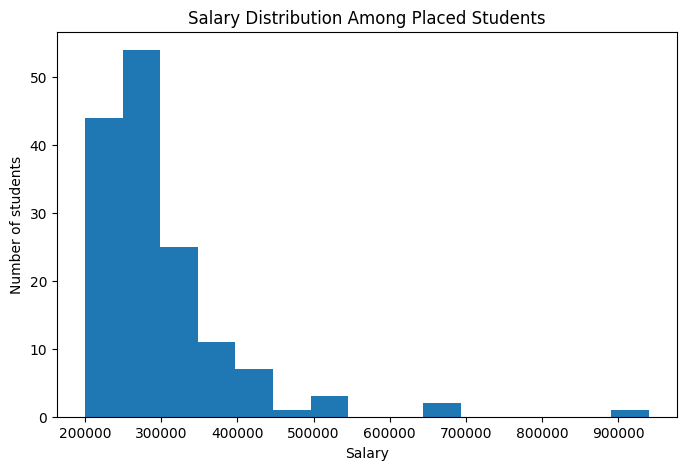

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(salary_df['salary'], bins=15)
plt.xlabel('Salary')
plt.ylabel('Number of students')
plt.title('Salary Distribution Among Placed Students')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_salary_train, X_salary_test, y_salary_train, y_salary_test = train_test_split(
    X_salary,
    y_salary,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_salary_train.shape)
print("Testing shape:", X_salary_test.shape)

Training shape: (118, 11)
Testing shape: (30, 11)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

numeric_features = X_salary_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_salary_train.select_dtypes(include=['object']).columns.tolist()

salary_preprocessor = ColumnTransformer([
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     categorical_features)
])

salary_model = Pipeline([
    ('preprocessor', salary_preprocessor),
    ('regressor', LinearRegression())
])

salary_model.fit(X_salary_train, y_salary_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['ssc_p', 'hsc_p', 'degree_p',
                                                   'etest_p', 'mba_p']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ssc_b', 'hsc_b', 'hsc_s',
                                                   'degree_t', 'workex',
                                                   'specialisation'])])),
                ('regressor', LinearRegression())])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

salary_pred = salary_model.predict(X_salary_test)

mae = mean_absolute_error(y_salary_test, salary_pred)
rmse = np.sqrt(mean_squared_error(y_salary_test, salary_pred))

print(f"MAE: ₹{mae:,.0f}")
print(f"RMSE: ₹{rmse:,.0f}")

MAE: ₹70,572
RMSE: ₹98,188


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_absolute_error
import numpy as np

rf_salary_model = Pipeline([
    ('preprocessor', salary_preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=3
    ))
])

cv_salary = KFold(n_splits=5,shuffle=True,random_state=42)

salary_cv_scores = cross_validate(
    rf_salary_model,
    X_salary_train,
    y_salary_train,
    cv=cv_salary,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error'
    }
)

print("Mean CV MAE:",round(-salary_cv_scores['test_mae'].mean()))
print("Mean CV RMSE:",round(-salary_cv_scores['test_rmse'].mean()))

Mean CV MAE: 55232
Mean CV RMSE: 87292


In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

cv_salary = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

salary_models = {
    'Linear Regression': Pipeline([
        ('preprocessor', salary_preprocessor),
        ('regressor', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', salary_preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42
        ))
    ])
}

for name, estimator in salary_models.items():
    scores = cross_validate(
        estimator,
        X_salary_train,
        y_salary_train,
        cv=cv_salary,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error'
        }
    )

    print(f"\n{name}")
    print(f"Mean CV MAE: {-scores['test_mae'].mean():,.0f}")
    print(f"Mean CV RMSE: {-scores['test_rmse'].mean():,.0f}")


Linear Regression
Mean CV MAE: 62,934
Mean CV RMSE: 93,488

Random Forest
Mean CV MAE: 55,232
Mean CV RMSE: 87,292


In [ ]:
# random forest preferred
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

best_salary_model = salary_models['Random Forest']
best_salary_model.fit(X_salary_train, y_salary_train)

salary_pred_rf = best_salary_model.predict(X_salary_test)

mae_rf = mean_absolute_error(y_salary_test, salary_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_salary_test, salary_pred_rf))

print(f"Test MAE: ₹{mae_rf:,.0f}")
print(f"Test RMSE: ₹{rmse_rf:,.0f}")

Test MAE: ₹67,423
Test RMSE: ₹94,771


In [ ]:
comparison = pd.DataFrame({'Actual Salary': y_salary_test,'Predicted Salary': salary_pred_rf})

comparison['Absolute Error'] = (
    comparison['Actual Salary'] -
    comparison['Predicted Salary']
).abs()

comparison = comparison.sort_values('Absolute Error',ascending=False)
comparison.head(10).round(0)

,Actual Salary,Predicted Salary,Absolute Error
177,650000.0,292257.0,357743.0
145,400000.0,256306.0,143694.0
95,420000.0,291023.0,128977.0
44,200000.0,308515.0,108515.0
19,236000.0,343796.0,107796.0
47,204000.0,311555.0,107555.0
56,240000.0,339210.0,99210.0
197,260000.0,349407.0,89407.0
101,380000.0,296977.0,83023.0
15,200000.0,279336.0,79336.0


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_rf = mean_absolute_error(y_salary_test, salary_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_salary_test, salary_pred_rf))

print(f"Test MAE: ₹{mae_rf:,.0f}")
print(f"Test RMSE: ₹{rmse_rf:,.0f}")

comparison['Error'] = (
    comparison['Predicted Salary'] -
    comparison['Actual Salary']
)

comparison.sort_values('Actual Salary',ascending=False).head(10).round(0)

Test MAE: ₹67,423
Test RMSE: ₹94,771


,Actual Salary,Predicted Salary,Absolute Error,Error
177,650000.0,292257.0,357743.0,-357743.0
95,420000.0,291023.0,128977.0,-128977.0
39,411000.0,335296.0,75704.0,-75704.0
145,400000.0,256306.0,143694.0,-143694.0
210,400000.0,344547.0,55453.0,-55453.0
101,380000.0,296977.0,83023.0,-83023.0
178,350000.0,335370.0,14630.0,-14630.0
28,350000.0,280924.0,69076.0,-69076.0
74,336000.0,362818.0,26818.0,26818.0
96,300000.0,242361.0,57639.0,-57639.0


In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# Same salary observations and same split as before
salary_df = pd.read_csv('/content/placement-data.csv')
salary_df = salary_df[
    (salary_df['status'] == 'Placed') &
    (salary_df['salary'].notna())
].copy()

# Model A: exclude gender
X_without_gender = salary_df.drop(
    columns=['sl_no', 'status', 'salary', 'gender']
)

# Model B: include gender
X_with_gender = salary_df.drop(
    columns=['sl_no', 'status', 'salary']
)

y_salary = salary_df['salary']

# Use the same row split for both experiments
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    salary_df.index,
    test_size=0.2,
    random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def make_salary_model(X):
    numeric = X.select_dtypes(
        include=['int64', 'float64']
    ).columns.tolist()

    categorical = X.select_dtypes(
        include=['object']
    ).columns.tolist()

    prep = ColumnTransformer([
        ('num', 'passthrough', numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical)
    ])

    return Pipeline([
        ('preprocessor', prep),
        ('regressor', RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42
        ))
    ])

for name, X_features in [
    ('Without gender', X_without_gender),
    ('With gender', X_with_gender)
]:
    X_train = X_features.loc[train_idx]
    y_train = y_salary.loc[train_idx]

    scores = cross_validate(
        make_salary_model(X_features),
        X_train,
        y_train,
        cv=cv,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error'
        }
    )

    print(f'\n{name}')
    print(f"CV MAE: {-scores['test_mae'].mean():,.0f}")
    print(f"CV RMSE: {-scores['test_rmse'].mean():,.0f}")


Without gender
CV MAE: 55,232
CV RMSE: 87,292

With gender
CV MAE: 55,854
CV RMSE: 87,494


In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

salary_pred = salary_model.predict(X_salary_test)

mae = mean_absolute_error(y_salary_test, salary_pred)
rmse = root_mean_squared_error(y_salary_test, salary_pred)

print(f"Test MAE: ₹{mae:,.0f}")
print(f"Test RMSE: ₹{rmse:,.0f}")

Test MAE: ₹70,572
Test RMSE: ₹98,188


In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Evaluate the selected Random Forest salary model
salary_pred_rf = best_salary_model.predict(X_salary_test)

mae_rf = mean_absolute_error(y_salary_test, salary_pred_rf)
rmse_rf = root_mean_squared_error(y_salary_test, salary_pred_rf)

print(f"Random Forest Test MAE: ₹{mae_rf:,.0f}")
print(f"Random Forest Test RMSE: ₹{rmse_rf:,.0f}")


Random Forest Test MAE: ₹67,423
Random Forest Test RMSE: ₹94,771


In [ ]:

import pandas as pd

def predict_student(student_details):
    # Convert the student's details into a DataFrame
    student = pd.DataFrame([student_details])

    # Predict placement probability and class
    placement_probability = best_model.predict_proba(student)[0, 1]
    placement_prediction = best_model.predict(student)[0]

    print(f"Placement probability: {placement_probability:.1%}")

    if placement_prediction == 1:
        print("Placement prediction: Placed")

        # Predict salary using the selected Random Forest model
        estimated_salary = best_salary_model.predict(student)[0]

        print(f"Estimated salary: ₹{estimated_salary:,.0f}")
        print("Actual salary may be higher or lower.")
    else:
        print("Placement prediction: Not placed")
        print("Salary estimate: Not provided by this workflow.")

    return {
        "placement_probability": placement_probability,
        "placement_prediction": int(placement_prediction),
        "estimated_salary": (
            float(best_salary_model.predict(student)[0])
            if placement_prediction == 1
            else None
        )
    }


In [ ]:

sample_student = {
    "ssc_p": 85.0,
    "hsc_p": 82.0,
    "ssc_b": "Central",
    "hsc_b": "Central",
    "hsc_s": "Science",
    "degree_p": 80.0,
    "degree_t": "Sci&Tech",
    "workex": "Yes",
    "etest_p": 78.0,
    "specialisation": "Mkt&Fin",
    "mba_p": 75.0
}

result = predict_student(sample_student)
print("\nResult:", result)


Placement probability: 99.7%
Placement prediction: Placed
Estimated salary: ₹318,612
Actual salary may be higher or lower.

Result: {'placement_probability': np.float64(0.9966807712492182), 'placement_prediction': 1, 'estimated_salary': 318611.7898629149}


In [ ]:

import joblib
from google.colab import files

# Save the complete fitted pipelines
joblib.dump(best_model, "placement_model.joblib")
joblib.dump(best_salary_model, "salary_model.joblib")

# Download both files to your computer
files.download("placement_model.joblib")
files.download("salary_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("salary_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>